# 05 · The polls themselves

Part 1 of the study plan (`docs/study_plan.md`): what the polls look like before comparing them with the results.
Built block by block: **coverage**, then trajectories, rank stability, pollsters and noise.

Input: `data/final/polls.csv` (notebook 04). Tables go to `results/tables/`, figures to `results/figures/`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
ELECTIONS = sorted(rows["election"].unique())

## 1 · Coverage

One row per poll: when, by whom, how big, how many scenarios, and its ballot scenario if it has one.

In [2]:
tested = rows[rows["share_status"] != "not_tested"]
ballot = tested[tested["ballot_scenario"]]
polls = rows.drop_duplicates("poll_id")[["election", "poll_id", "institute", "institute_family", "sponsor", "date",
                                          "days_before", "weeks_before", "phase", "rolling", "sample_size"]].copy()
polls["n_scenarios"] = polls["poll_id"].map(rows.groupby("poll_id")["scenario_id"].nunique())
polls["has_ballot_scenario"] = polls["poll_id"].isin(ballot["poll_id"])
polls["n_candidates_ballot"] = polls["poll_id"].map(ballot.groupby("poll_id")["candidate"].nunique())
polls["rolling"] = polls["rolling"].fillna(False).astype(bool)

by_election = polls.groupby("election").agg(
    polls=("poll_id", "size"), pollsters=("institute_family", "nunique"),
    first_poll=("date", "min"), last_poll=("date", "max"),
    days_before_first=("days_before", "max"), days_before_last=("days_before", "min"),
    with_ballot_scenario=("has_ballot_scenario", "sum"), rolling=("rolling", "sum"),
    multi_scenario=("n_scenarios", lambda x: int((x > 1).sum())))
phases = pd.crosstab(polls["election"], polls["phase"])
coverage = by_election.join(phases)
coverage.to_csv(TABLES / "coverage_by_election.csv")
coverage

,polls,pollsters,first_poll,last_poll,days_before_first,days_before_last,with_ballot_scenario,rolling,multi_scenario,before the official list,official list to two weeks before,last two weeks
election,,,,,,,,,,,,
2002,98,6,1999-05-07,2002-04-18,1080,3,49,0,0,81,5,12
2007,107,6,2005-01-21,2007-04-20,821,2,107,0,1,69,20,18
2012,124,8,2007-11-02,2012-04-17,1633,5,116,0,19,95,17,12
2017,148,12,2012-10-12,2017-04-21,1654,2,109,0,66,103,23,22
2022,231,11,2017-10-18,2022-04-08,1635,2,184,32,76,161,37,33


### Polls per pollster

Pollster families (Sofres, TNS Sofres, Kantar → one family).

In [3]:
by_pollster = pd.crosstab(polls["institute_family"], polls["election"], margins=True, margins_name="all")
by_pollster = by_pollster.sort_values("all", ascending=False)
by_pollster.to_csv(TABLES / "coverage_by_pollster.csv")
by_pollster

election,2002,2007,2012,2017,2022,all
institute_family,,,,,,
all,98,107,124,148,231,708
Ifop,16,22,37,40,42,157
Ipsos,21,25,20,17,25,108
OpinionWay,0,0,15,13,51,79
Harris Interactive,0,0,12,11,44,67
BVA,10,11,12,20,13,66
Kantar (Sofres),23,17,6,11,4,61
CSA,23,20,13,2,0,58
Elabe,0,0,0,18,25,43


### Pace: polls per week before the vote

The last 52 weeks. Week 1 is the last seven days before the first round.

share of each election's polls in the last 4 and 8 weeks:


,4,8
election,,
2002,0.24,0.44
2007,0.30,0.55
2012,0.20,0.38
2017,0.26,0.43
2022,0.26,0.43


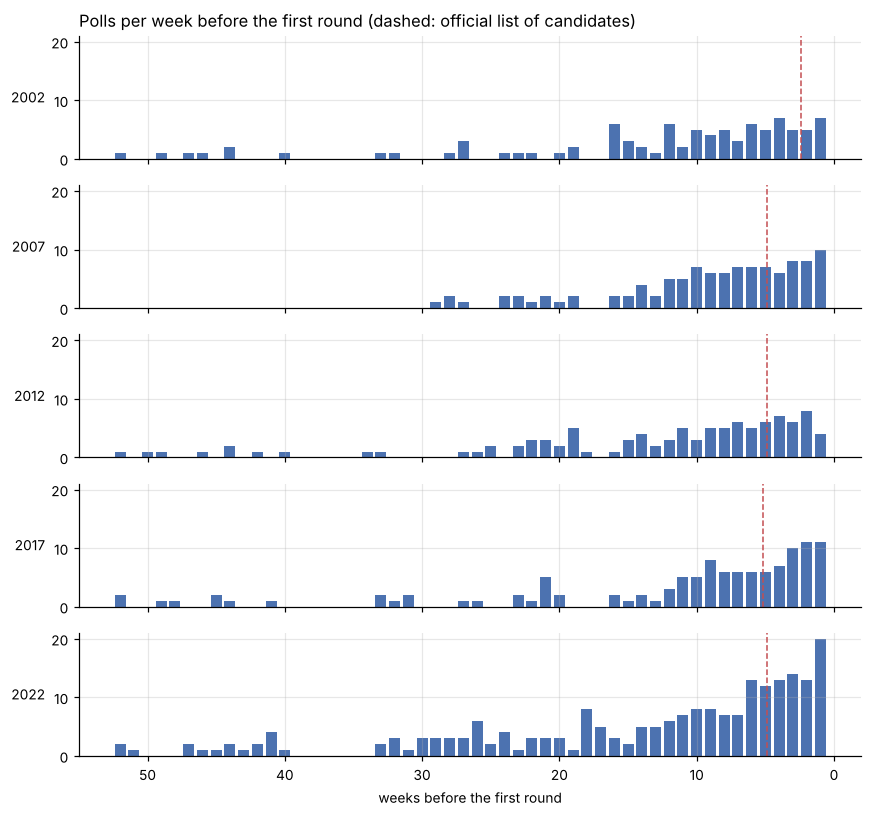

In [4]:
weekly = (polls[polls["weeks_before"] <= 52].groupby(["election", "weeks_before"]).size()
          .unstack("election").reindex(range(1, 53), fill_value=0).fillna(0).astype(int))
weekly.to_csv(TABLES / "coverage_polls_per_week.csv")

fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(8, 7.5), sharex=True, sharey=True)
for ax, e in zip(axes, ELECTIONS):
    ax.bar(weekly.index, weekly[e], width=0.8, color="#4c72b0")
    lst = (calendar.loc[e, "first_round"] - calendar.loc[e, "official_list"]).days / 7
    ax.axvline(lst, color="#c44e52", lw=1, ls="--")
    ax.set_ylabel(str(e), rotation=0, ha="right", va="center")
axes[0].set_title("Polls per week before the first round (dashed: official list of candidates)", loc="left")
axes[-1].set_xlabel("weeks before the first round")
axes[-1].invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURES / "coverage_polls_per_week.png")
print("share of each election's polls in the last 4 and 8 weeks:")
pd.DataFrame({w: polls[polls["weeks_before"] <= w].groupby("election").size() / polls.groupby("election").size()
              for w in (4, 8)}).round(2)

### Sample sizes (2017 and 2022)

The base of respondents giving a voting intention, as Wikipedia gives it. Absent before 2017.

In [5]:
n = polls.dropna(subset=["sample_size"])
samples = n.groupby("election")["sample_size"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "min", "10%", "50%", "90%", "max"]]
samples["rolling_median"] = n[n["rolling"]].groupby("election")["sample_size"].median()
samples["one_off_median"] = n[~n["rolling"]].groupby("election")["sample_size"].median()
samples.to_csv(TABLES / "coverage_sample_sizes.csv")
samples.round(0)

,count,min,10%,50%,90%,max,rolling_median,one_off_median
election,,,,,,,,
2017,147.0,586.0,926.0,1401.0,5696.0,21326.0,NaN,1401.0
2022,230.0,893.0,1005.0,1502.0,2600.0,16228.0,1578.0,1483.0


### Candidates tested in the ballot scenario

How many candidates a poll offers, against how many were on the ballot. In 2007 and 2012, Wikipedia leaves out
small candidates in many polls (see the spot check).

In [6]:
on_ballot = rows.groupby("election")["slot"].apply(lambda s: s.dropna().nunique())
cands = polls[polls["has_ballot_scenario"]].groupby(["election", "phase"], observed=True)["n_candidates_ballot"].median().unstack()
cands.insert(0, "on_ballot", on_ballot)
cands.to_csv(TABLES / "coverage_candidates_tested.csv")
cands

phase,on_ballot,before the official list,official list to two weeks before,last two weeks
election,,,,
2002,16,16.0,16.0,16.0
2007,12,11.0,12.0,12.0
2012,10,10.0,10.0,10.0
2017,11,9.0,11.0,11.0
2022,12,14.0,12.0,12.0


## 2 · Trajectories

Each poll's ballot scenario gives one share per final candidacy (its `slot`: the candidate, or whoever stands in for
them, e.g. Juppé for Fillon). The poll average is a Gaussian kernel mean of the polls (bandwidth 10 days, at least 3
polls nearby); the band is the spread of the polls around it (± 1 SD). Shares as published (raw); below-threshold
shares at half their bound. The six candidates with the best results are drawn; the dot at 0 is the result.

Markers: **takeovers** (dotted: from this poll on, the ballot scenarios test the final candidate in person, after
others had filled their slot, e.g. Fillon after Juppé and Sarkozy; this can precede the official nomination, since a
poll's scenario with the final candidate is preferred) and **withdrawals** (dashed: the last poll testing a candidate
who will not be on the ballot, if they still polled 1% or more in their last month). Withdrawals change the set of
candidates offered, and with it the concentration of the poll, without any voter changing their mind.

In [7]:
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
b = ballot.copy()
b["value"] = np.where(b["share_status"] == "value", b["share"], b["share_upper_bound"] * 0.5)
slot_polls = b.dropna(subset=["slot"]).groupby(["election", "poll_id", "slot"], as_index=False).agg(
    value=("value", "sum"), days_before=("days_before", "first"))

GRID = np.arange(0, 366, 2)
traj = pd.concat([average.by_candidate(g, "value", GRID).assign(election=e)
                  for e, g in slot_polls.groupby("election")], ignore_index=True)
weekly_traj = traj[traj["days_before"] % 14 == 0]          # every two weeks, for the committed table
weekly_traj.round(2).to_csv(TABLES / "trajectories_poll_average.csv", index=False)

top6 = results.sort_values("share", ascending=False).groupby("election").head(6)

# takeovers: the final candidate takes over a slot filled by others before
stood_in = b[b["slot"].notna() & (b["candidate"] != b["slot"])].groupby(["election", "slot"])["days_before"].min()
in_person = b[b["candidate"] == b["slot"]]
takeovers = []
for (e, slot), last_stand_in in stood_in.items():
    after = in_person[(in_person["election"] == e) & (in_person["slot"] == slot) & (in_person["days_before"] < last_stand_in)]
    if len(after):
        takeovers.append(dict(election=e, candidate=slot, days_before=after["days_before"].max(), kind="takeover"))
takeovers = pd.DataFrame(takeovers).query("days_before <= 365")
# withdrawals: last poll of a candidate who will not be on the ballot
extra = b[b["slot"].isna()]
last = extra.sort_values("days_before").groupby(["election", "candidate"]).agg(
    days_before=("days_before", "min"), polls=("poll_id", "nunique"))
recent = extra.merge(last["days_before"].rename("last").reset_index()).query("days_before <= last + 30")
last["share_last_month"] = recent.groupby(["election", "candidate"])["share"].mean()
withdrawals = (last[(last["share_last_month"] >= 1) & (last["polls"] >= 3)].reset_index()
               .query("days_before <= 365").assign(kind="withdrawal"))
events = pd.concat([takeovers, withdrawals])[["election", "kind", "candidate", "days_before", "share_last_month"]]
events.round(1).sort_values(["election", "days_before"], ascending=[True, False]).to_csv(TABLES / "trajectories_entries_withdrawals.csv", index=False)
events.sort_values(["election", "days_before"], ascending=[True, False])

,election,kind,candidate,days_before,share_last_month
0,2002,withdrawal,Charles Pasqua,22,2.270833
0,2007,takeover,Dominique Voynet,199,NaN
1,2007,takeover,Ségolène Royal,199,NaN
3,2012,takeover,François Hollande,344,NaN
2,2012,takeover,Eva Joly,304,NaN
4,2012,takeover,Philippe Poutou,232,NaN
2,2012,withdrawal,Jean-Louis Borloo,230,7.000000
1,2012,withdrawal,Dominique de Villepin,83,2.000000
3,2017,withdrawal,Cécile Duflot,189,2.500000
6,2017,takeover,François Fillon,157,NaN


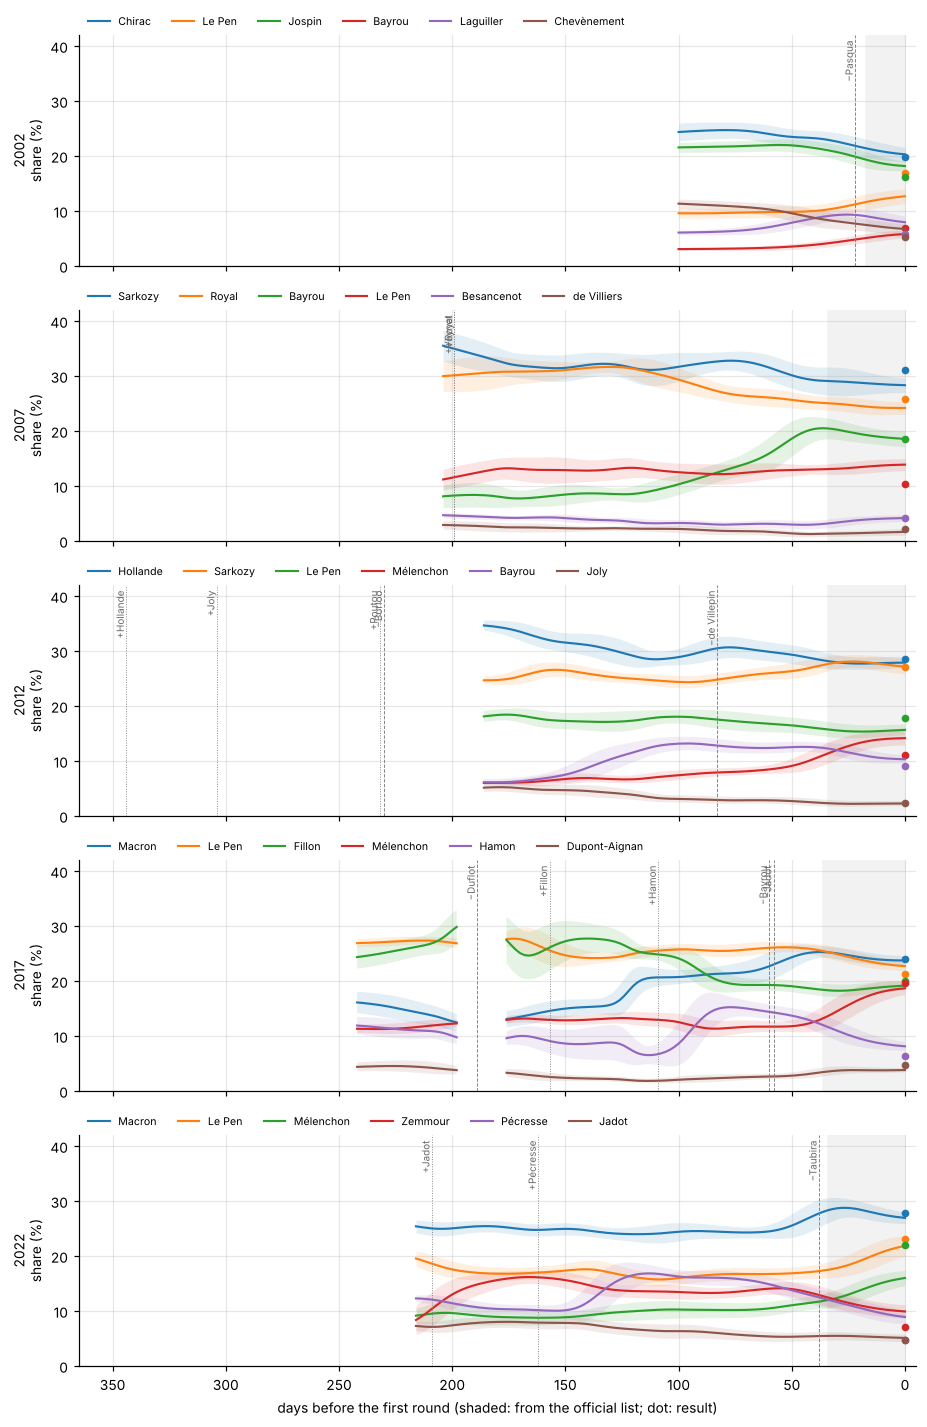

In [8]:
COLORS = plt.get_cmap("tab10").colors
surname = lambda name: name.split(" ", 1)[1] if " " in name else name
fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(8.5, 13), sharex=True)
for ax, e in zip(axes, ELECTIONS):
    for i, r in enumerate(top6[top6["election"] == e].itertuples()):
        t = traj[(traj["election"] == e) & (traj["slot"] == r.candidate)]
        ax.plot(t["days_before"], t["mean"], color=COLORS[i], lw=1.4, label=surname(r.candidate))
        ax.fill_between(t["days_before"], t["mean"] - t["sd"], t["mean"] + t["sd"], color=COLORS[i], alpha=0.12, lw=0)
        ax.plot(0, r.share, "o", color=COLORS[i], ms=4)
    for r in events[events["election"] == e].itertuples():
        ax.axvline(r.days_before, color="grey", lw=0.6, ls=":" if r.kind == "takeover" else "--")
        ax.text(r.days_before, ax.get_ylim()[1] if False else 41, ("+" if r.kind == "takeover" else "−") + surname(r.candidate),
                rotation=90, fontsize=6.5, va="top", ha="right", color="dimgrey")
    lst = (calendar.loc[e, "first_round"] - calendar.loc[e, "official_list"]).days
    ax.axvspan(0, lst, color="#f2f2f2", zorder=0)
    ax.set_ylim(0, 42)
    ax.set_ylabel(f"{e}\nshare (%)")
    ax.legend(loc="upper left", fontsize=7, ncol=6, frameon=False, bbox_to_anchor=(0, 1.13))
axes[-1].set_xlim(365, -5)
axes[-1].set_xlabel("days before the first round (shaded: from the official list; dot: result)")
fig.tight_layout()
fig.savefig(FIGURES / "trajectories.png")

### Volatility

How much the poll average moves from one week to the next: mean absolute change over seven days, averaged over the
six leading candidates, by phase. Movement of the average, not of single polls.

In [9]:
t7 = traj[traj["days_before"] % 7 == 0].sort_values("days_before")
t7 = t7.merge(top6[["election", "candidate"]].rename(columns={"candidate": "slot"}))
t7["weekly_change"] = t7.groupby(["election", "slot"])["mean"].diff().abs()
t7 = timeline.add_time(t7.assign(date=lambda d: d["election"].map(calendar["first_round"]) - pd.to_timedelta(d["days_before"], "D")), calendar)
volatility = t7.groupby(["election", "phase"], observed=True)["weekly_change"].mean().unstack().round(2)
volatility["last 12 months"] = t7[t7["days_before"] <= 365].groupby("election")["weekly_change"].mean().round(2)
volatility.to_csv(TABLES / "trajectories_volatility.csv")
volatility

phase,before the official list,official list to two weeks before,last two weeks,last 12 months
election,,,,
2002,0.54,NaN,0.74,0.57
2007,0.55,0.51,0.26,0.53
2012,0.63,0.50,0.32,0.59
2017,0.88,1.18,0.55,0.88
2022,0.62,1.31,0.99,0.69
